# Семинар 5 — Многоклассовая классификация текстов: BoW / TF-IDF + MLP

**Цель:** собрать полный пайплайн классификации текстов «как в жизни» — от сырых предложений до обученной нейросети и матрицы ошибок. Мы реализуем разреженные представления (Bag of Words, TF-IDF) **вручную**, обучим линейную модель и MLP на чистом PyTorch, а в конце попробуем обучаемые эмбеддинги (`EmbeddingBag`).

**Карта семинара**

| № | Тема |
|---|---|
| 1 | Данные: предложения SQuAD по 8 темам, EDA, стратифицированный train/test split |
| 2 | Векторизация: BoW и TF-IDF руками (словарь, матрица счётчиков, IDF) |
| 3 | Бейзлайн: линейная модель на PyTorch, `Dataset`/`DataLoader`, цикл обучения |
| 4 | MLP на PyTorch: скрытый слой, кривые, матрица ошибок |
| 5 | Бонус: `EmbeddingBag` — обучаемые эмбеддинги вместо one-hot |
| 6 | Итоги: сравнение всех методов |

**Как работать.** Запускайте ячейки сверху вниз (`Shift + Enter`). Ячейки с ✏️ — это задания: допишите код, и `assert` ниже сразу проверит результат. Всё остальное (GIVEN) можно просто запускать.

> **Связь с лекцией 6.** В лекции мы разобрали, *как устроены* BoW, TF-IDF и эмбеддинги. Здесь мы соберём первые два своими руками и применим к реальной задаче. Убедимся, что даже простая линейная модель поверх TF-IDF — очень сильный бейзлайн, который нейросети обыгрывают не всегда и не сразу.

**Правила.** Только **PyTorch** и NumPy/SciPy — никаких высокоуровневых ML-библиотек: весь код виден и понятен. Пишем device-agnostic (CPU / CUDA / MPS) и с фиксированным seed.

## 0. Импорты и общие настройки

In [1]:
import os, re, json, time, collections, random, warnings
warnings.filterwarnings('ignore')

import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, Dataset

from nltk.tokenize import sent_tokenize

# ---------- воспроизводимость ----------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available()
                      else 'cpu')

plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (8, 4)

print('torch  :', torch.__version__)
print('numpy  :', np.__version__)
print('device :', device)

torch  : 2.2.0.dev20230914+cu121
numpy  : 1.21.2
device : cuda


## 1. Данные: предложения SQuAD по темам

Возьмём датасет **SQuAD v2.0** — он лежит в корне репозитория как `squad-v2.0.json`. Нам он нужен не как задача вопрос-ответ, а как корпус английского текста: у каждой статьи есть заголовок-тема.

Выберем 8 тем и возьмём из каждой по 300 предложений. Каждое предложение — это **документ** с меткой-темой. Итого 2400 документов и 8 классов.

Если файла нет, он скачается автоматически:

* <https://rajpurkar.github.io/SQuAD-explorer/dataset/train-v2.0.json>

In [2]:
TOKEN_RE = re.compile(r"[a-z0-9']+")

def tokenize(text):
    '''Слова в нижнем регистре: буквы, цифры, апостроф.'''
    return TOKEN_RE.findall(text.lower())

def find_squad():
    '''Ищем squad-v2.0.json рядом с ноутбуком; если нет — скачиваем официальный train-v2.0.'''
    for path in ['squad-v2.0.json', '../squad-v2.0.json', '../../squad-v2.0.json']:
        if os.path.exists(path):
            return path
    import urllib.request
    url = 'https://rajpurkar.github.io/SQuAD-explorer/dataset/train-v2.0.json'
    print('squad-v2.0.json не найден, скачиваю с', url)
    urllib.request.urlretrieve(url, 'squad-v2.0.json')
    return 'squad-v2.0.json'

squad = json.load(open(find_squad()))['data']

CATEGORIES = ['Buddhism', 'New_York_City', 'American_Idol', 'Israel',
              'Portugal', 'Southampton', 'Greece', 'Middle_Ages']
PER_CLASS = 300

# собираем предложения по выбранным темам
by_title = {c: [] for c in CATEGORIES}
for article in squad:
    if article['title'] in by_title:
        for p in article['paragraphs']:
            by_title[article['title']] += sent_tokenize(p['context'])

docs, labels = [], []
rng = random.Random(SEED)
for label, c in enumerate(CATEGORIES):
    sents = by_title[c][:]
    rng.shuffle(sents)
    sents = sents[:PER_CLASS]
    docs += sents
    labels += [label] * len(sents)
labels = np.array(labels)

print('всего документов:', len(docs), '| классов:', len(CATEGORIES))
print('пример документа:')
print(' ', docs[0][:150], '...')

всего документов: 2400 | классов: 8
пример документа:
  Keeping these precepts keeps the cultivator from rebirth in the four woeful realms of existence. ...


### 1.1. Разведочный анализ (EDA)

Посмотрим на два графика: баланс классов и распределение длин предложений. Баланс важен — иначе точность (accuracy) будет обманчивой.

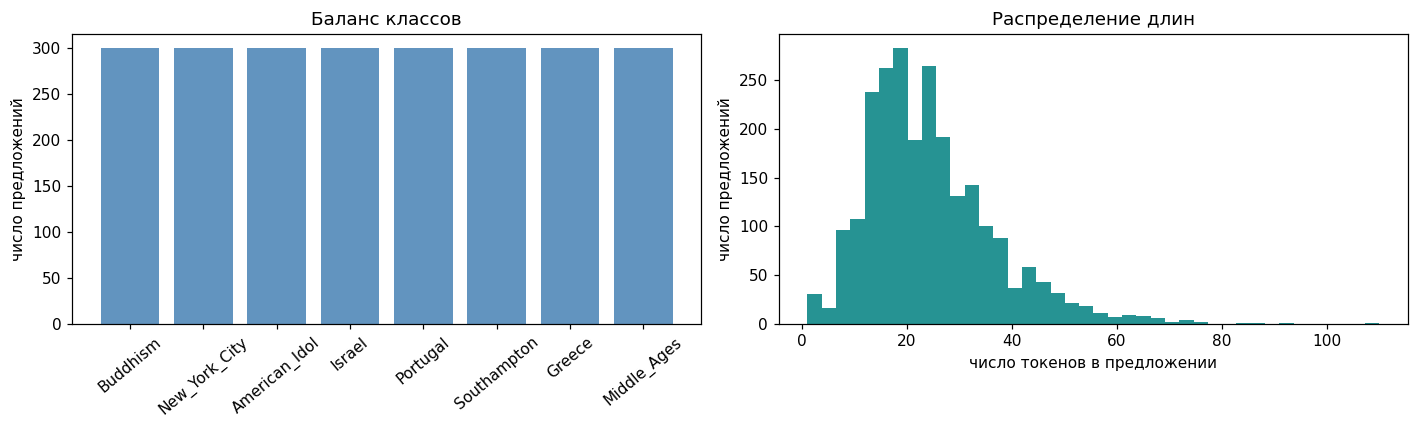

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = np.bincount(labels)
axes[0].bar(CATEGORIES, counts, color='steelblue', alpha=0.85)
axes[0].set_ylabel('число предложений')
axes[0].set_title('Баланс классов')
axes[0].tick_params(axis='x', rotation=40)

lengths = [len(tokenize(d)) for d in docs]
axes[1].hist(lengths, bins=40, color='teal', alpha=0.85)
axes[1].set_xlabel('число токенов в предложении')
axes[1].set_ylabel('число предложений')
axes[1].set_title('Распределение длин')

plt.tight_layout()
plt.show()

In [12]:
# ✏️ Задание 1 — посчитайте статистику датасета сами
def describe_dataset(y, docs):
    '''Вернуть (counts, mean_len):
       counts   — np.array с числом документов в каждом классе, (np.bincount)
       mean_len — среднее число токенов в документе (float).'''    
    counts = ...      # <-- YOUR CODE HERE
    mean_len = ...    # <-- YOUR CODE HERE
    return counts, mean_len

counts, mean_len = describe_dataset(labels, docs)

assert counts.sum() == len(docs), 'counts должен суммироваться в число документов'
assert len(counts) == len(CATEGORIES), 'должно быть по счётчику на каждый класс'
assert 10 < mean_len < 40, f'средняя длина {mean_len:.1f} выглядит подозрительно'
print(f'Задание 1 OK ✓ | классов = {len(counts)}, всего = {counts.sum()}, '
      f'средняя длина = {mean_len:.1f} токенов')

Задание 1 OK ✓ | классов = 8, всего = 2400, средняя длина = 23.9 токенов


### 1.2. Train / test split (стратифицированный, руками)

Делим датасет на 80/20 **с сохранением пропорций классов** (stratified). Внутри каждого класса перемешиваем примеры и откладываем 20 % в тест.

Зачем стратификация: при случайном делении маленькие классы могли бы «перекосить» тест, и accuracy стала бы ненадёжной метрикой.

In [18]:
# ✏️ Задание 2 — стратифицированное деление на train/test
def stratified_split(y, test_size=0.2, seed=SEED):
    '''Вернуть (idx_train, idx_test) — np.array индексов.
       Для каждого класса: перемешать его примеры, test_size уходят в тест.'''
    rng = np.random.default_rng(seed)
    idx_train, idx_test = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        # <-- YOUR CODE HERE (перемешайте idx и разложите по train/test, np.random.shuffle)
    return np.array(idx_train), np.array(idx_test)

idx_train, idx_test = stratified_split(labels)

assert len(idx_train) + len(idx_test) == len(labels), 'потеряли примеры'
assert set(idx_train).isdisjoint(idx_test), 'индексы train и test пересекаются'
# баланс должен сохраниться
tr_frac = np.bincount(labels[idx_train]) / len(idx_train)
assert np.allclose(tr_frac, 1 / len(CATEGORIES), atol=0.02), 'классы в train не сбалансированы'
print('Задание 2 OK ✓ | train =', len(idx_train), '| test =', len(idx_test))

Задание 2 OK ✓ | train = 1920 | test = 480


In [19]:
train_docs = [docs[i] for i in idx_train]
test_docs = [docs[i] for i in idx_test]
y_train, y_test = labels[idx_train], labels[idx_test]

print('train:', len(train_docs), '| test:', len(test_docs))
print('баланс train:', np.bincount(y_train))
print('баланс test :', np.bincount(y_test))

train: 1920 | test: 480
баланс train: [240 240 240 240 240 240 240 240]
баланс test : [60 60 60 60 60 60 60 60]


---
## 2. Векторизация: BoW и TF-IDF руками

**Bag of Words (BoW).** Документ → вектор счётчиков по словарю: $x_d = (\text{count}(w_1, d), \dots, \text{count}(w_V, d))$. Размерность = размер словаря, вектор разреженный.

**TF-IDF.** Взвешиваем счётчики: частые-везде слова гасим, редкие-информативные усиливаем:

$$\text{tfidf}(t, d) = \underbrace{\frac{\text{count}(t,d)}{|d|}}_{\text{tf}} \cdot \underbrace{\log\frac{1+N}{1+\text{df}(t)} + 1}_{\text{idf}}$$

Здесь $N$ — число документов, $\text{df}(t)$ — в скольких документах встретилось слово $t$.

Всё считаем сами. Словарь строим **только по train** — иначе тестовая статистика «протечёт» в обучение (data leakage).

In [20]:
def build_vocab(docs, min_df=2):
    '''Словарь: слово -> индекс. Оставляем слова, встретившиеся минимум в min_df документах.'''
    df = collections.Counter()
    for d in docs:
        df.update(set(tokenize(d)))          # set => считаем документы, а не вхождения
    words = sorted([w for w, c in df.items() if c >= min_df])
    return {w: i for i, w in enumerate(words)}

word2id = build_vocab(train_docs, min_df=2)
id2word = [None] * len(word2id)
for w, i in word2id.items():
    id2word[i] = w
V = len(word2id)
print('размер словаря V =', V)

размер словаря V = 3699


In [8]:
# ✏️ Задание 3 — матрица счётчиков BoW
def build_bow(docs, word2id):
    '''Вернуть разреженную матрицу (n_docs x V) в формате CSR со счётчиками слов.
       Подсказка: scipy.sparse.csr_matrix((values, (rows, cols)), shape=(n_docs, V)).'''
    rows, cols, vals = [], [], []
    for i, d in enumerate(docs):
        ...   # <-- YOUR CODE HERE: посчитайте счётчики слов документа i и добавьте в rows/cols/vals
    return sp.csr_matrix((vals, (rows, cols)), shape=(len(docs), len(word2id)), dtype=np.float32)

Xb_train = build_bow(train_docs, word2id)
Xb_test = build_bow(test_docs, word2id)

assert Xb_train.shape == (len(train_docs), V), 'неверная форма BoW'
assert Xb_train.nnz > 0, 'матрица пустая'
assert Xb_train[0].sum() == len([t for t in tokenize(train_docs[0]) if t in word2id]), \
    'число слов в первом документе не совпало'
print('Задание 3 OK ✓ | BoW', Xb_train.shape,
      '| ненулевых =', f'{Xb_train.nnz:,}',
      '| плотность =', f'{Xb_train.nnz / (Xb_train.shape[0] * V):.3%}')

Задание 3 OK ✓ | BoW (1920, 3698) | ненулевых = 34,973 | плотность = 0.493%


### 2.1. IDF руками

Самый важный компонент TF-IDF — IDF. Посчитаем его по формуле и соберём TF-IDF-матрицу: `tfidf = tf * idf`, где `tf` — счётчики, нормированные на длину документа.

In [9]:
# ✏️ Задание 4 — реализуйте IDF по формуле
def manual_idf(X_binary):
    '''idf(t) = log((1 + N) / (1 + df(t))) + 1
       X_binary — матрица «документ x слово» из 0/1 (сравнение X > 0 даст bool).
       Вернуть np.array длины V.'''
    N = X_binary.shape[0]
    df = ...    # <-- YOUR CODE HERE: в скольких документах встречается каждое слово
    idf = ...   # <-- YOUR CODE HERE
    return idf

idf = manual_idf(Xb_train > 0)
df = np.asarray((Xb_train > 0).sum(axis=0)).ravel()

assert idf.shape == (V,), 'размер вектора idf не совпал'
assert idf.min() >= 1.0, 'idf не может быть меньше 1 при таком сглаживании'
assert idf[np.argmin(df)] > idf[np.argmax(df)], 'редкие слова должны иметь больший idf'
print('Задание 4 OK ✓ | частое слово idf =', round(float(idf[np.argmax(df)]), 2),
      '| редкое слово idf =', round(float(idf[np.argmin(df)]), 2))

Задание 4 OK ✓ | частое слово idf = 1.17 | редкое слово idf = 7.46


In [10]:
# собираем TF-IDF: sublinear tf (1+log count) -> нормировка на длину -> * idf -> L2-нормировка
def tfidf_matrix(X_counts, idf, sublinear=True):
    tf = X_counts.copy()
    if sublinear:
        tf.data = 1.0 + np.log(tf.data)               # лог-сжатие больших счётчиков
    row_len = np.asarray(tf.sum(axis=1)).ravel()
    T = sp.diags(1.0 / np.maximum(row_len, 1.0)) @ tf
    T = T @ sp.diags(idf)                             # умножаем на idf по столбцам
    norms = np.sqrt(np.asarray(T.multiply(T).sum(axis=1)).ravel()) + 1e-9
    return sp.diags(1.0 / norms) @ T                  # L2-нормировка строк

Xt_train = tfidf_matrix(Xb_train, idf)
Xt_test = tfidf_matrix(Xb_test, idf)
print('TF-IDF (train):', Xt_train.shape)

# самое частое и самое редкое слово по IDF — проверим интуицию
order = np.argsort(idf)
print('Слова с наименьшим IDF (встречаются почти везде):')
for j in order[:10]:
    print(f'  {id2word[j]:14s} idf={idf[j]:.2f}')
print('\nСлова с наибольшим IDF (редкие, информативные):')
for j in order[-10:]:
    print(f'  {id2word[j]:14s} idf={idf[j]:.2f}')

TF-IDF (train): (1920, 3698)
Слова с наименьшим IDF (встречаются почти везде):
  the            idf=1.17
  of             idf=1.49
  and            idf=1.61
  in             idf=1.67
  to             idf=2.08
  a              idf=2.17
  as             idf=2.61
  is             idf=2.66
  by             idf=2.76
  was            idf=2.78

Слова с наибольшим IDF (редкие, информативные):
  implementation idf=7.46
  impermanence   idf=7.46
  immigrant      idf=7.46
  immediate      idf=7.46
  imitating      idf=7.46
  ideology       idf=7.46
  identifiable   idf=7.46
  ideals         idf=7.46
  huns           idf=7.46
  zoning         idf=7.46


---
## 3. Бейзлайн: линейная модель на PyTorch

Прежде чем строить глубокую сеть, получим **бейзлайн**. Линейная модель (один слой `nn.Linear` без нелинейности) поверх TF-IDF — это тот результат, который MLP обязана побить, чтобы оправдать свою сложность.

Заодно соберём инфраструктуру обучения на PyTorch, которая понадобится дальше:

* `TensorDataset` + `DataLoader` (`shuffle=True` для train);
* цикл: `zero_grad → forward → loss → backward → step`;
* accuracy считаем в `eval()`-режиме и `torch.no_grad()`.

Матрицу TF-IDF переводим в плотные тензоры — на нашей задаче ($3684$ признака) это допустимо. Для сотен тысяч признаков так делать нельзя.

In [11]:
# разреженный TF-IDF -> плотные тензоры
X_train_t = torch.tensor(Xt_train.toarray(), dtype=torch.float32)
X_test_t  = torch.tensor(Xt_test.toarray(),  dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t  = torch.tensor(y_test,  dtype=torch.long)

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=0, pin_memory=(device.type == 'cuda'))
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=256,
                          shuffle=False, num_workers=0, pin_memory=(device.type == 'cuda'))

in_dim = X_train_t.shape[1]
print('признаков (размер словаря):', in_dim)
print('обучающих примеров        :', len(X_train_t))
print('тестовых примеров         :', len(X_test_t))


# ---------- метрики пишем сами, вручную ----------
def accuracy_score(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))

def macro_f1(y_true, y_pred, n_classes):
    '''Macro-F1: F1 по каждому классу, усреднённый по классам.'''
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    f1s = []
    for k in range(n_classes):
        tp = np.sum((y_true == k) & (y_pred == k))
        fp = np.sum((y_true != k) & (y_pred == k))
        fn = np.sum((y_true == k) & (y_pred != k))
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1s.append(2 * prec * rec / (prec + rec) if (prec + rec) else 0.0)
    return float(np.mean(f1s))

results = {}   # accuracy всех методов — для итогового графика

признаков (размер словаря): 3698
обучающих примеров        : 1920
тестовых примеров         : 480


In [12]:
# ✏️ Задание 5 — шаг обучения и оценка
def train_one_epoch(model, loader, optimizer, criterion):
    '''Один проход по loader в режиме обучения. Вернуть средний loss.'''
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        ...   # <-- YOUR CODE HERE (5 шагов: zero_grad / forward / loss / backward / step)
    return total / n

@torch.no_grad()
def evaluate(model, loader):
    '''Accuracy на loader без градиентов. Вернуть (accuracy, список предсказаний).'''
    model.eval()
    correct, preds = 0, []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        ...   # <-- YOUR CODE HERE
    return correct / len(loader.dataset), preds


# ---- GIVEN: универсальный цикл обучения ----
def train_model(model, epochs=15, lr=1e-3, weight_decay=0.0, verbose=False):
    torch.manual_seed(SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    history = {'loss': [], 'acc': []}
    for epoch in range(epochs):
        loss = train_one_epoch(model, train_loader, optimizer, criterion)
        acc, _ = evaluate(model, test_loader)
        history['loss'].append(loss)
        history['acc'].append(acc)
        if verbose and (epoch + 1) % 5 == 0:
            print(f'  эпоха {epoch+1:2d}: loss={loss:.4f} acc={acc:.4f}')
    return history


# ---- GIVEN: обучаем линейный бейзлайн ----
torch.manual_seed(SEED)
linear = nn.Linear(in_dim, len(CATEGORIES)).to(device)
hist_lin = train_model(linear, epochs=40, lr=1e-2)

acc_lin, pred_lin = evaluate(linear, test_loader)
results['Linear TF-IDF'] = acc_lin
assert acc_lin > 0.80, f'линейный бейзлайн дал {acc_lin:.4f}; проверьте Задание 5'
print(f'Задание 5 OK ✓ | Linear TF-IDF acc={acc_lin:.4f}  '
      f'macro-F1={macro_f1(y_test, pred_lin, len(CATEGORIES)):.4f}')

Задание 5 OK ✓ | Linear TF-IDF acc=0.8167  macro-F1=0.8127


In [13]:
# сравним линейную модель на BoW против TF-IDF
Xb_train_t = torch.tensor(Xb_train.toarray(), dtype=torch.float32)
Xb_test_t  = torch.tensor(Xb_test.toarray(),  dtype=torch.float32)
bow_loader = DataLoader(TensorDataset(Xb_train_t, y_train_t), batch_size=64, shuffle=True)
bow_test   = DataLoader(TensorDataset(Xb_test_t, y_test_t),  batch_size=256)

torch.manual_seed(SEED)
lin_bow = nn.Linear(in_dim, len(CATEGORIES)).to(device)
opt_bow = torch.optim.Adam(lin_bow.parameters(), lr=1e-2)
for _ in range(40):
    train_one_epoch(lin_bow, bow_loader, opt_bow, nn.CrossEntropyLoss())
acc_bow, _ = evaluate(lin_bow, bow_test)
results['Linear BoW'] = acc_bow
print(f'Linear BoW     acc={acc_bow:.4f}')
print(f'Linear TF-IDF  acc={acc_lin:.4f}')

Linear BoW     acc=0.8125
Linear TF-IDF  acc=0.8167


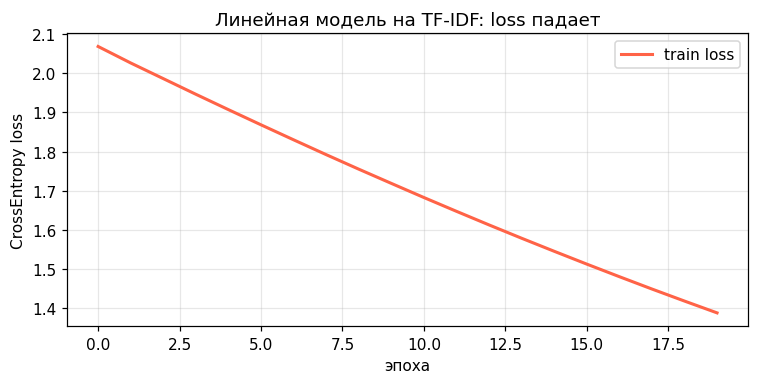

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(hist_lin['loss'], color='tomato', lw=2, label='train loss')
ax.set_xlabel('эпоха'); ax.set_ylabel('CrossEntropy loss')
ax.set_title('Линейная модель на TF-IDF: loss падает')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

---
## 4. MLP на PyTorch

**Зачем MLP, если линейная модель уже хороша?** Линейный слой комбинирует слова строго по отдельности. MLP добавляет скрытый слой с нелинейностью (ReLU) и может ловить **паттерны**: «*buddha* и *meditation* вместе ⇒ буддизм».

Но важная деталь: у нас **разреженные признаки высокой размерности**. На такой задаче нейросеть не всегда выигрывает у линейной модели — и это нормальный, честный результат.

In [15]:
# ✏️ Задание 6 — соберите MLP на PyTorch
def make_mlp(in_dim, hidden=64, n_classes=len(CATEGORIES), dropout=0.0):
    '''Linear(in_dim, hidden) -> ReLU -> Dropout(dropout) -> Linear(hidden, n_classes).
       Вернуть nn.Sequential, перемещённую на device.'''
    layers = [
        ...   # <-- YOUR CODE HERE (добавьте слои в список)
    ]
    return nn.Sequential(*layers).to(device)

model_check = make_mlp(in_dim)
out = model_check(torch.randn(5, in_dim).to(device))
assert tuple(out.shape) == (5, len(CATEGORIES)), \
    f'ожидали (5, {len(CATEGORIES)}), получили {tuple(out.shape)}'
print('Задание 6 OK ✓ | форма выхода модели:', tuple(out.shape))

Задание 6 OK ✓ | форма выхода модели: (5, 8)


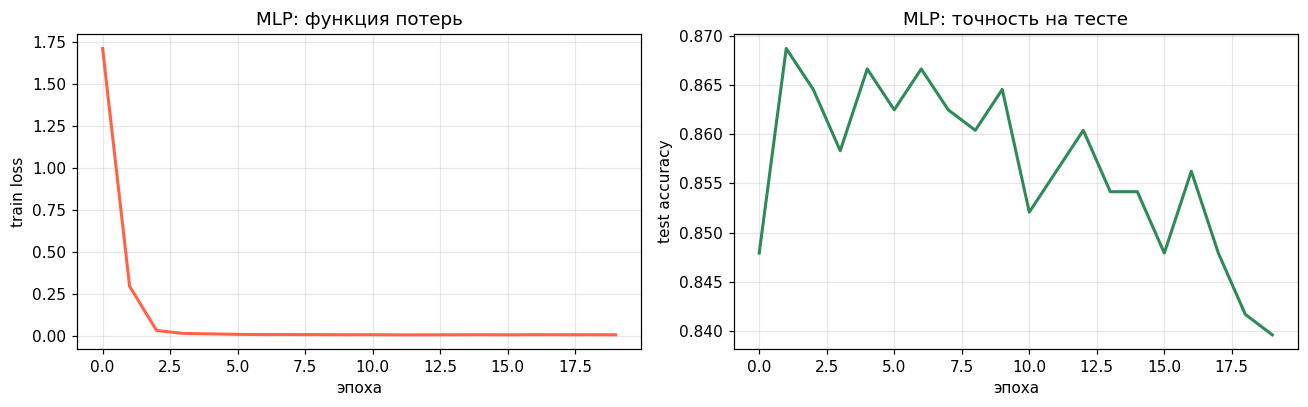

MLP (64) acc=0.8396  macro-F1=0.8370


In [16]:
torch.manual_seed(SEED)
mlp = make_mlp(in_dim, hidden=64, dropout=0.0)
hist_mlp = train_model(mlp, epochs=20, lr=1e-2)
acc_mlp, pred_mlp = evaluate(mlp, test_loader)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(hist_mlp['loss'], color='tomato', lw=2)
axes[0].set_xlabel('эпоха'); axes[0].set_ylabel('train loss')
axes[0].set_title('MLP: функция потерь'); axes[0].grid(alpha=0.3)
axes[1].plot(hist_mlp['acc'], color='seagreen', lw=2)
axes[1].set_xlabel('эпоха'); axes[1].set_ylabel('test accuracy')
axes[1].set_title('MLP: точность на тесте'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f'MLP (64) acc={acc_mlp:.4f}  macro-F1={macro_f1(y_test, pred_mlp, len(CATEGORIES)):.4f}')

In [17]:
# ✏️ Задание 7 — подберите конфигурацию MLP
def sweep_mlp(configs=((32, 0.0), (64, 0.0), (64, 0.3), (128, 0.3))):
    '''Для каждой пары (hidden, dropout) обучить MLP и вернуть {config: test_accuracy}.'''
    out = {}
    for hidden, dropout in configs:
        ...   # <-- YOUR CODE HERE (make_mlp + train_model + evaluate)
    return out

mlp_scores = sweep_mlp()

assert len(mlp_scores) >= 3, 'проверьте хотя бы 3 конфигурации'
assert max(mlp_scores.values()) > 0.84, 'лучшая конфигурация слишком слабая'
best_cfg = max(mlp_scores, key=mlp_scores.get)
print('Задание 7 OK ✓ | лучшая конфигурация:', best_cfg,
      '| accuracy =', round(mlp_scores[best_cfg], 4))

Задание 7 OK ✓ | лучшая конфигурация: (64, 0.3) | accuracy = 0.8562


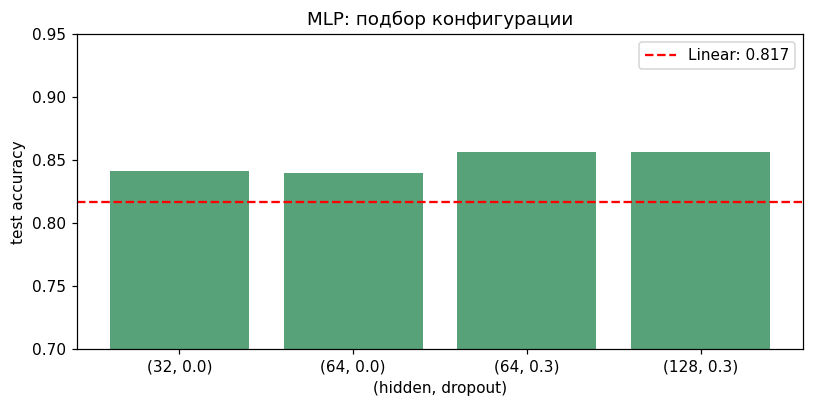

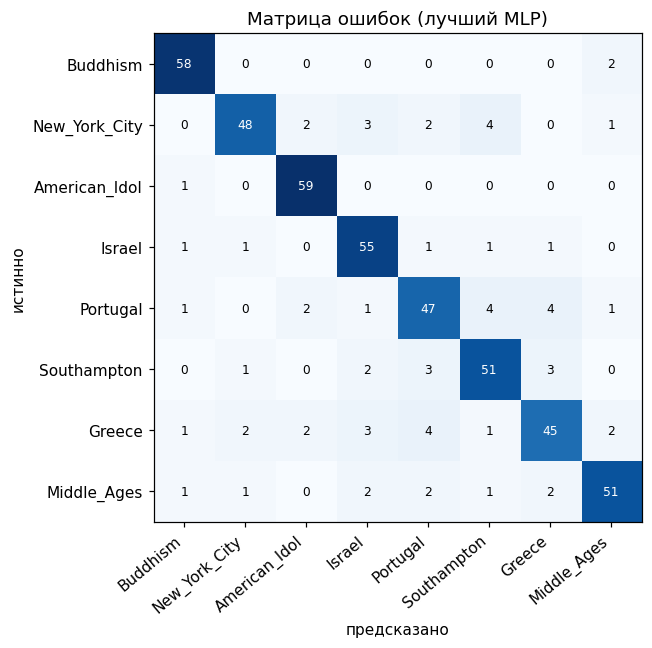

лучший MLP: hidden=64, dropout=0.3, acc=0.8625


In [18]:
# лучшая конфигурация -> финальная модель, кривые и матрица ошибок
torch.manual_seed(SEED)
best_hidden, best_dropout = best_cfg
model = make_mlp(in_dim, hidden=best_hidden, dropout=best_dropout)
hist_best = train_model(model, epochs=20, lr=1e-3)
acc_best, pred_best = evaluate(model, test_loader)
results['PyTorch MLP (best)'] = acc_best

fig, ax = plt.subplots(figsize=(7.5, 3.8))
labels_cfg = [str(c) for c in mlp_scores]
vals_cfg = list(mlp_scores.values())
ax.bar(labels_cfg, vals_cfg, color='seagreen', alpha=0.8)
ax.axhline(acc_lin, color='red', ls='--', label=f'Linear: {acc_lin:.3f}')
ax.set_ylim(0.7, 0.95)
ax.set_xlabel('(hidden, dropout)'); ax.set_ylabel('test accuracy')
ax.set_title('MLP: подбор конфигурации')
ax.legend()
plt.tight_layout(); plt.show()

# --- матрица ошибок вручную ---
cm = np.zeros((len(CATEGORIES), len(CATEGORIES)), dtype=int)
for t, p in zip(y_test, pred_best):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(CATEGORIES)))
ax.set_xticklabels(CATEGORIES, rotation=40, ha='right')
ax.set_yticks(range(len(CATEGORIES)))
ax.set_yticklabels(CATEGORIES)
ax.set_xlabel('предсказано'); ax.set_ylabel('истинно')
ax.set_title('Матрица ошибок (лучший MLP)')
for i in range(len(CATEGORIES)):
    for j in range(len(CATEGORIES)):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                color='black' if cm[i, j] < cm.max() / 2 else 'white')
plt.tight_layout(); plt.show()

print(f'лучший MLP: hidden={best_hidden}, dropout={best_dropout}, acc={acc_best:.4f}')

---
## 5. Бонус: `EmbeddingBag` — обучаемые эмбеддинги

До этого слова были **индексами** в огромном разреженном векторе. Альтернатива из лекции 6 — **обучаемые эмбеддинги**: каждому слову соответствует плотный вектор длины $d$, и сеть учит эти векторы сама.

```text
   предложение: [id1, id2, id3, ...]
        │
        ▼  nn.EmbeddingBag(mode='mean')
   средний вектор слов  ∈ R^d
        │
        ▼  nn.Linear(d, n_classes)
   логиты по 8 темам
```

Это `mean-pooling` эмбеддингов + линейный слой, обученные end-to-end. Плюс: нет огромного разреженного словаря. Минус: обучаемых параметров $V \times d$.

In [19]:
# словарь для эмбеддингов строим по train
counter = collections.Counter()
for d in train_docs:
    counter.update(tokenize(d))
emb_vocab = [w for w, c in counter.most_common() if c >= 2]
emb_word2id = {w: i + 1 for i, w in enumerate(emb_vocab)}   # 0 — padding
VOCAB_SIZE = len(emb_vocab) + 1

class TextDataset(Dataset):
    '''Каждый документ -> tensor id-шников слов.'''
    def __init__(self, docs, y):
        self.docs, self.y = docs, y
    def __len__(self):
        return len(self.docs)
    def __getitem__(self, i):
        ids = [emb_word2id[t] for t in tokenize(self.docs[i]) if t in emb_word2id]
        return torch.tensor(ids, dtype=torch.long), int(self.y[i])

def collate_batch(batch):
    '''Склеиваем разные по длине документы в один батч через padding.'''
    seqs, ys = zip(*batch)
    padded = nn.utils.rnn.pad_sequence(seqs, batch_first=True)
    return padded, torch.tensor(ys, dtype=torch.long)

emb_train = DataLoader(TextDataset(train_docs, y_train), batch_size=64,
                       shuffle=True, collate_fn=collate_batch)
emb_test = DataLoader(TextDataset(test_docs, y_test), batch_size=256,
                      collate_fn=collate_batch)

print('размер словаря эмбеддингов:', VOCAB_SIZE)

размер словаря эмбеддингов: 3816


In [20]:
# ✏️ Задание 8 — модель Bag-of-Embeddings
class BagClassifier(nn.Module):
    def __init__(self, vocab_size, dim=64, n_classes=len(CATEGORIES)):
        super().__init__()
        self.embedding = ...   # <-- YOUR CODE HERE: nn.EmbeddingBag(vocab_size, dim, mode='mean')
        self.fc = ...          # <-- YOUR CODE HERE: линейный слой dim -> n_classes
    def forward(self, x):
        ...                    # <-- YOUR CODE HERE
        return ...

bag = BagClassifier(VOCAB_SIZE).to(device)
out = bag(torch.randint(1, VOCAB_SIZE, (5, 7)).to(device))
assert tuple(out.shape) == (5, len(CATEGORIES)), f'получили {tuple(out.shape)}'
print('Задание 8 OK ✓ | форма выхода:', tuple(out.shape))

Задание 8 OK ✓ | форма выхода: (5, 8)


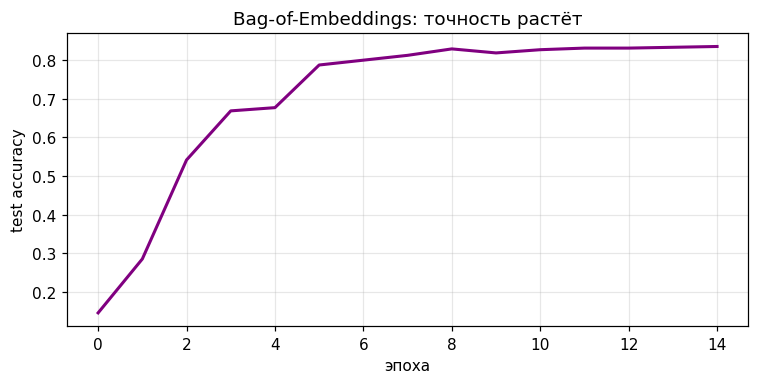

Bag-of-Embeddings accuracy = 0.8354


In [21]:
# ---- GIVEN: обучение Bag-of-Embeddings ----
torch.manual_seed(SEED)
bag = BagClassifier(VOCAB_SIZE, dim=64).to(device)
opt_bag = torch.optim.Adam(bag.parameters(), lr=1e-2)
crit = nn.CrossEntropyLoss()

bag_hist = []
for epoch in range(15):
    bag.train()
    for xb, yb in emb_train:
        xb, yb = xb.to(device), yb.to(device)
        opt_bag.zero_grad()
        loss = crit(bag(xb), yb)
        loss.backward()
        opt_bag.step()
    acc, _ = evaluate(bag, emb_test)
    bag_hist.append(acc)

results['Bag-of-Embeddings'] = bag_hist[-1]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(bag_hist, color='purple', lw=2)
ax.set_xlabel('эпоха'); ax.set_ylabel('test accuracy')
ax.set_title('Bag-of-Embeddings: точность растёт')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f'Bag-of-Embeddings accuracy = {bag_hist[-1]:.4f}')

---
## 6. Итоги

Сведём все методы на один график.

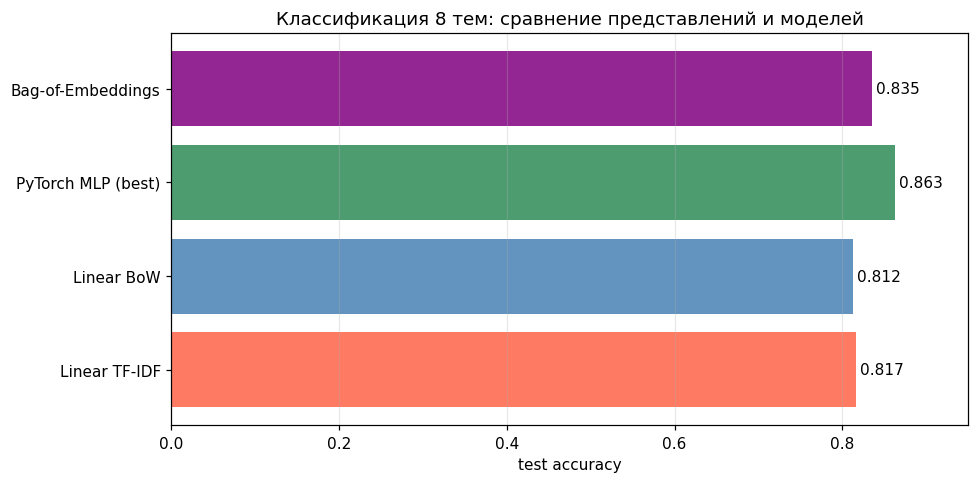

Итог:
  PyTorch MLP (best)       0.8625
  Bag-of-Embeddings        0.8354
  Linear TF-IDF            0.8167
  Linear BoW               0.8125


In [22]:
names = list(results.keys())
vals = list(results.values())

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['tomato' if 'TF-IDF' in n else 'purple' if 'Bag' in n
          else 'seagreen' if 'MLP' in n else 'steelblue' for n in names]
bars = ax.barh(names, vals, color=colors, alpha=0.85)
for b, v in zip(bars, vals):
    ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f'{v:.3f}',
            va='center', fontsize=10)
ax.set_xlim(0, 0.95)
ax.set_xlabel('test accuracy')
ax.set_title('Классификация 8 тем: сравнение представлений и моделей')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print('Итог:')
for n, v in sorted(results.items(), key=lambda kv: -kv[1]):
    print(f'  {n:24s} {v:.4f}')

### Что мы увидели

1. **TF-IDF обыгрывает BoW.** Веса IDF гасят служебные слова и усиливают информативные — линейная модель сразу получает качественные признаки.
2. **Линейный бейзлайн очень силён.** Один слой поверх TF-IDF — серьёзный соперник; MLP выигрывает лишь немного, а иногда и проигрывает.
3. **MLP полезен, но не волшебный.** Скрытый слой добавляет нелинейность и помогает комбинировать слова, но на разреженных признаках выигрыш скромный.
4. **Dropout борется с переобучением.** Сеть быстро запоминает train — dropout и регуляризация возвращают качество на тесте.
5. **Обучаемые эмбеддинги (`EmbeddingBag`) работают «из коробки»**, но на 2400 документах уступают TF-IDF: им нужно больше данных, чтобы выучить хорошие векторы слов.

### ✏️ Что попробовать самому

1. **Размер словаря.** Меняйте `min_df` (1, 2, 5) — как это влияет на скорость и качество?
2. **Биграммы.** Добавьте в словарь не только слова, но и пары соседних слов — BoW станет «мешком слов и пар». Помогает ли?
3. **Архитектура MLP.** Два скрытых слоя, другой размер, `Tanh` вместо `ReLU` — есть ли выигрыш?
4. **Регуляризация.** Добавьте `weight_decay` в `Adam` (параметр `train_model`) и сравните с dropout.
5. **Больше данных.** Возьмите не 300, а 1000 предложений на класс — сократится ли разрыв между TF-IDF и эмбеддингами?
6. **Свои эмбеддинги из лекции 6.** Обучите GloVe/FastText на большом корпусе (SQuAD целиком) и подайте усреднённый вектор документа в MLP вместо TF-IDF.

### Полезные ссылки

- [Lecture 6 — Векторизация текста](../lecture6/text_vectorization.ipynb): BoW, TF-IDF, pPMI+SVD, word2vec, FastText, GloVe «с нуля».
- [PyTorch: `nn.EmbeddingBag`](https://pytorch.org/docs/stable/generated/torch.nn.EmbeddingBag.html)
- [Bag of Tricks for Efficient Text Classification (Joulin et al., 2016)](https://arxiv.org/abs/1607.01759)

---
> **Резюме одной строкой.** Тексты → BoW/TF-IDF (руками) → линейная модель или MLP на PyTorch → честное сравнение; даже простая линейная модель поверх TF-IDF — сильный бейзлайн, а нейросети выигрывают, только когда данных и нелинейности достаточно.